
# E-Commerce Delivery & Logistics Performance Analysis

## Week 2 — Advanced Python Analysis

### Objective
Analyze delivery performance using the Olist e-commerce dataset, validate relationships between datasets, compare weekday and state-level delivery outcomes, and investigate the relationship between delivery outcomes and customer review scores.

### Key Analysis Areas
1. Join-key validation and duplicate checks
2. Weekday-wise delivery performance
3. State-wise delivery performance validation
4. Customer review scores by delivery outcome
5. Business findings, limitations, and Week 3 plan

### KPI Definitions
- **Eligible delivered orders:** Orders with delivered status and valid actual and estimated delivery timestamps.
- **On-time delivery:** An eligible order delivered on or before its estimated delivery date.
- **Late delivery:** An eligible order delivered after its estimated delivery date.
- **Delivery duration:** Time between purchase and actual customer delivery, measured in days.

### Data Integrity Rules
- Raw CSV files will remain unchanged.
- Order-level KPIs will use one row per order.
- Order items and multiple review records will be handled carefully to avoid inflating order counts.
- Findings will describe observed patterns, not assume unproven causes.
- Carrier-level analysis is excluded because the dataset has no carrier identifier.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Define project and data paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DATA.exists())
print("Reports folder exists:", REPORTS_DIR.exists())
print("Python libraries imported successfully.")


Project root: C:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main
Raw data folder exists: True
Reports folder exists: True
Python libraries imported successfully.


In [2]:

# Load raw datasets without modifying the source files
orders = pd.read_csv(
    RAW_DATA / "olist_orders_dataset.csv",
    low_memory=False
)

order_items = pd.read_csv(
    RAW_DATA / "olist_order_items_dataset.csv",
    low_memory=False
)

products = pd.read_csv(
    RAW_DATA / "olist_products_dataset.csv",
    low_memory=False
)

reviews = pd.read_csv(
    RAW_DATA / "olist_order_reviews_dataset.csv",
    low_memory=False
)

customers = pd.read_csv(
    RAW_DATA / "olist_customers_dataset.csv",
    low_memory=False
)

# Display dataset dimensions
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Reviews": reviews,
    "Customers": customers
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Orders: 99,441 rows × 8 columns
Order Items: 112,650 rows × 7 columns
Products: 32,951 rows × 9 columns
Reviews: 99,224 rows × 7 columns
Customers: 99,441 rows × 5 columns


In [3]:

# 1. Check uniqueness of primary keys
print("=== PRIMARY KEY VALIDATION ===")
print("Orders: unique order IDs =", orders["order_id"].nunique())
print("Products: unique product IDs =", products["product_id"].nunique())
print("Customers: unique customer IDs =", customers["customer_id"].nunique())

print("\n=== DUPLICATE KEY COUNTS ===")
print("Duplicate order IDs:",
      orders["order_id"].duplicated().sum())
print("Duplicate product IDs:",
      products["product_id"].duplicated().sum())
print("Duplicate customer IDs:",
      customers["customer_id"].duplicated().sum())

# 2. Check unmatched foreign keys
order_ids = set(orders["order_id"].dropna())
product_ids = set(products["product_id"].dropna())
customer_ids = set(customers["customer_id"].dropna())

print("\n=== UNMATCHED KEY COUNTS ===")
print(
    "Order items with unmatched order IDs:",
    (~order_items["order_id"].isin(order_ids)).sum()
)
print(
    "Order items with unmatched product IDs:",
    (~order_items["product_id"].isin(product_ids)).sum()
)
print(
    "Orders with unmatched customer IDs:",
    (~orders["customer_id"].isin(customer_ids)).sum()
)
print(
    "Reviews with unmatched order IDs:",
    (~reviews["order_id"].isin(order_ids)).sum()
)

# 3. Check order and review row multiplicity
print("\n=== RELATIONSHIP CHECKS ===")
print(
    "Orders containing multiple item rows:",
    (order_items.groupby("order_id").size() > 1).sum()
)
print(
    "Orders containing multiple review rows:",
    (reviews.groupby("order_id").size() > 1).sum()
)


=== PRIMARY KEY VALIDATION ===
Orders: unique order IDs = 99441
Products: unique product IDs = 32951
Customers: unique customer IDs = 99441

=== DUPLICATE KEY COUNTS ===
Duplicate order IDs: 0
Duplicate product IDs: 0
Duplicate customer IDs: 0

=== UNMATCHED KEY COUNTS ===
Order items with unmatched order IDs: 0
Order items with unmatched product IDs: 0
Orders with unmatched customer IDs: 0
Reviews with unmatched order IDs: 0

=== RELATIONSHIP CHECKS ===
Orders containing multiple item rows: 9803
Orders containing multiple review rows: 547


In [ ]:

# Work on a separate copy; raw orders remain unchanged
delivery = orders.copy()

# Convert delivery-related fields to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    delivery[col] = pd.to_datetime(delivery[col], errors="coerce")

# Count missing or invalid dates
print("=== DELIVERY TIMESTAMP VALIDATION ===")
for col in date_columns:
    print(f"{col}: {delivery[col].isna().sum():,} missing/invalid values")

# Check order statuses
print("\n=== ORDER STATUS COUNTS ===")
print(delivery["order_status"].value_counts(dropna=False))

# Eligible orders: delivered status and valid actual and estimated dates
eligible_mask = (
    delivery["order_status"].eq("delivered")
    & delivery["order_delivered_customer_date"].notna()
    & delivery["order_estimated_delivery_date"].notna()
)

eligible = delivery.loc[eligible_mask].copy()

# Diagnose delivered orders excluded from the eligible delivery analysis
delivered_mask = delivery["order_status"].eq("delivered")

print("\\n=== ELIGIBILITY DIAGNOSTICS ===")
print("All delivered orders:", f"{delivered_mask.sum():,}")
print(
    "Delivered orders with missing actual delivery date:",
    f"{(delivered_mask & delivery['order_delivered_customer_date'].isna()).sum():,}"
)
print(
    "Delivered orders with missing estimated delivery date:",
    f"{(delivered_mask & delivery['order_estimated_delivery_date'].isna()).sum():,}"
)
print("Eligible delivered orders:", f"{len(eligible):,}")
print(
    "Delivered orders excluded by eligibility filter:",
    f"{delivered_mask.sum() - len(eligible):,}"
)


# Compare actual and estimated delivery timestamps
eligible["delivery_outcome"] = np.where(
    eligible["order_delivered_customer_date"]
    <= eligible["order_estimated_delivery_date"],
    "On time or early",
    "Late"
)

print("\n=== ELIGIBLE DELIVERY SUMMARY ===")
print("Total orders:", f"{len(delivery):,}")
print("Eligible delivered orders:", f"{len(eligible):,}")
print("On time or early:", f"{eligible['delivery_outcome'].eq('On time or early').sum():,}")
print("Late:", f"{eligible['delivery_outcome'].eq('Late').sum():,}")
print(
    "On-time rate:",
    f"{eligible['delivery_outcome'].eq('On time or early').mean() * 100:.2f}%"
)


In [5]:

# Create delivery duration in days
eligible["delivery_duration_days"] = (
    eligible["order_delivered_customer_date"]
    - eligible["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Identify the weekday when each order was purchased
eligible["purchase_weekday"] = (
    eligible["order_purchase_timestamp"].dt.day_name()
)

# Set weekday order for consistent reporting
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Summarize delivery performance by purchase weekday
weekday_summary = (
    eligible.groupby("purchase_weekday")
    .agg(
        eligible_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_duration_days", "mean"),
        late_orders=("delivery_outcome", lambda s: s.eq("Late").sum()),
        on_time_orders=(
            "delivery_outcome",
            lambda s: s.eq("On time or early").sum()
        )
    )
    .reindex(weekday_order)
)

weekday_summary["late_delivery_rate_pct"] = (
    weekday_summary["late_orders"]
    / weekday_summary["eligible_orders"]
    * 100
)

weekday_summary["on_time_rate_pct"] = (
    weekday_summary["on_time_orders"]
    / weekday_summary["eligible_orders"]
    * 100
)

display(weekday_summary.round(2))


,eligible_orders,average_delivery_days,late_orders,on_time_orders,late_delivery_rate_pct,on_time_rate_pct
purchase_weekday,,,,,,
Monday,15701,12.00,1421,14280,9.05,90.95
Tuesday,15502,12.08,1316,14186,8.49,91.51
Wednesday,15074,12.44,1176,13898,7.80,92.20
Thursday,14322,12.74,1084,13238,7.57,92.43
Friday,13684,13.57,1156,12528,8.45,91.55
Saturday,10555,13.36,802,9753,7.60,92.40
Sunday,11632,11.96,871,10761,7.49,92.51


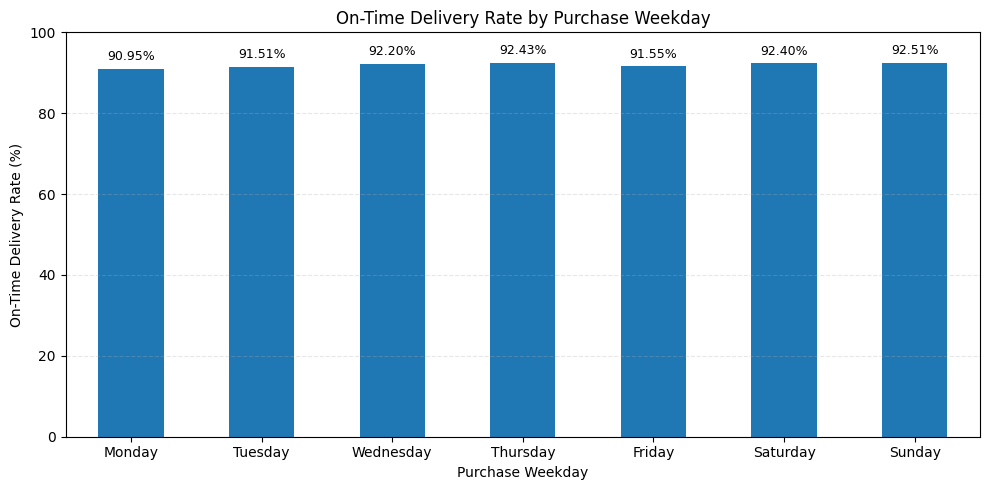

In [6]:

# Weekday-wise on-time delivery rate chart
fig, ax = plt.subplots(figsize=(10, 5))

weekday_summary["on_time_rate_pct"].plot(
    kind="bar",
    ax=ax,
    rot=0
)

ax.set_title("On-Time Delivery Rate by Purchase Weekday")
ax.set_xlabel("Purchase Weekday")
ax.set_ylabel("On-Time Delivery Rate (%)")
ax.set_ylim(0, 100)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=9
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

# Join eligible orders to customer state.
# Validate that each order has exactly one customer record.
state_delivery = eligible.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("=== CUSTOMER STATE JOIN VALIDATION ===")
print("Rows before join:", f"{len(eligible):,}")
print("Rows after join:", f"{len(state_delivery):,}")
print("Unmatched customer records:", (state_delivery["_merge"] != "both").sum())

# Summarize state-wise performance
state_summary = (
    state_delivery.groupby("customer_state")
    .agg(
        eligible_orders=("order_id", "nunique"),
        on_time_orders=(
            "delivery_outcome",
            lambda s: s.eq("On time or early").sum()
        ),
        late_orders=(
            "delivery_outcome",
            lambda s: s.eq("Late").sum()
        ),
        average_delivery_days=("delivery_duration_days", "mean")
    )
)

state_summary["on_time_rate_pct"] = (
    state_summary["on_time_orders"]
    / state_summary["eligible_orders"]
    * 100
)

state_summary["late_delivery_rate_pct"] = (
    state_summary["late_orders"]
    / state_summary["eligible_orders"]
    * 100
)

# Smallest samples can produce unstable rates, so show sample sizes
print("\n=== 10 STATES WITH LOWEST ON-TIME RATES ===")
display(
    state_summary
    .sort_values("on_time_rate_pct")
    .head(10)
    .round(2)
)


=== CUSTOMER STATE JOIN VALIDATION ===
Rows before join: 96,470
Rows after join: 96,470
Unmatched customer records: 0

=== 10 STATES WITH LOWEST ON-TIME RATES ===


,eligible_orders,on_time_orders,late_orders,average_delivery_days,on_time_rate_pct,late_delivery_rate_pct
customer_state,,,,,,
AL,397,302,95,24.54,76.07,23.93
MA,717,576,141,21.57,80.33,19.67
PI,476,400,76,19.46,84.03,15.97
CE,1279,1083,196,21.27,84.68,15.32
SE,335,284,51,21.52,84.78,15.22
BA,3256,2799,457,19.34,85.96,14.04
RJ,12350,10686,1664,15.31,86.53,13.47
TO,274,239,35,17.66,87.23,12.77
PA,946,829,117,23.77,87.63,12.37


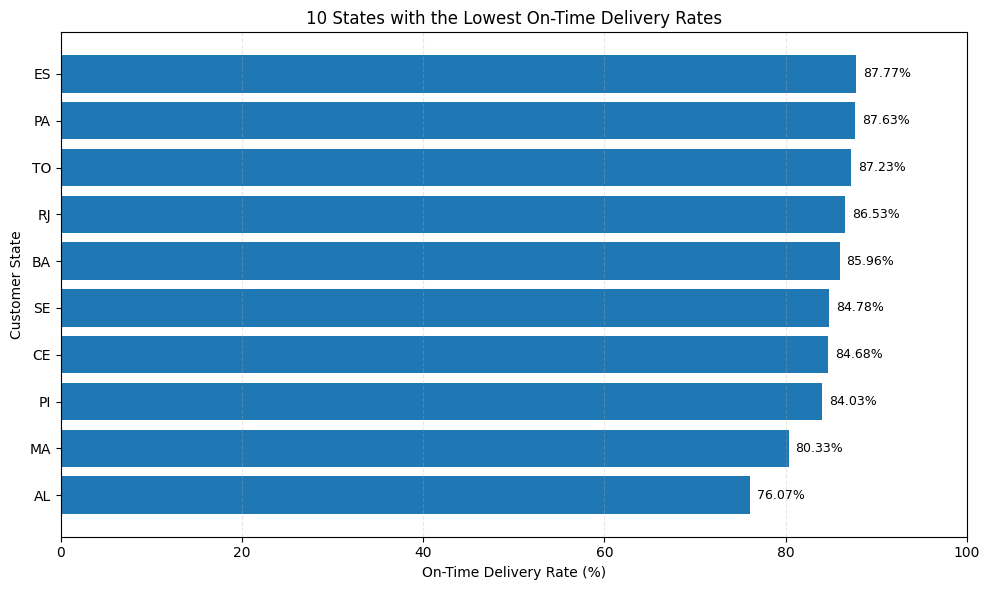

In [8]:

# Select the 10 states with the lowest on-time delivery rates
lowest_states = (
    state_summary
    .sort_values("on_time_rate_pct")
    .head(10)
    .sort_values("on_time_rate_pct", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    lowest_states.index,
    lowest_states["on_time_rate_pct"]
)

ax.set_title("10 States with the Lowest On-Time Delivery Rates")
ax.set_xlabel("On-Time Delivery Rate (%)")
ax.set_ylabel("Customer State")
ax.set_xlim(0, 100)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

# Keep only the fields required for review analysis
reviews_analysis = reviews[
    ["order_id", "review_score"]
].copy()

# Convert review scores to numeric; invalid values become missing
reviews_analysis["review_score"] = pd.to_numeric(
    reviews_analysis["review_score"],
    errors="coerce"
)

# Summarize reviews to one row per order
review_by_order = (
    reviews_analysis
    .dropna(subset=["order_id", "review_score"])
    .groupby("order_id", as_index=False)
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
)

print("=== REVIEW AGGREGATION VALIDATION ===")
print("Raw review rows:", f"{len(reviews):,}")
print("Orders with at least one valid review score:",
      f"{review_by_order['order_id'].nunique():,}")
print("Orders with multiple valid review scores:",
      f"{review_by_order['review_count'].gt(1).sum():,}")
print("Duplicate order IDs after aggregation:",
      f"{review_by_order['order_id'].duplicated().sum():,}")

# Merge order-level review summary with eligible delivery records
review_delivery = eligible.merge(
    review_by_order,
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\n=== DELIVERY-REVIEW JOIN VALIDATION ===")
print("Eligible delivery orders:", f"{len(eligible):,}")
print("Rows after review join:", f"{len(review_delivery):,}")
print("Orders with a matched review:",
      f"{review_delivery['_merge'].eq('both').sum():,}")
print("Orders without a valid review score:",
      f"{review_delivery['_merge'].eq('left_only').sum():,}")


=== REVIEW AGGREGATION VALIDATION ===
Raw review rows: 99,224
Orders with at least one valid review score: 98,673
Orders with multiple valid review scores: 547
Duplicate order IDs after aggregation: 0

=== DELIVERY-REVIEW JOIN VALIDATION ===
Eligible delivery orders: 96,470
Rows after review join: 96,470
Orders with a matched review: 95,824
Orders without a valid review score: 646


In [10]:

# Compare order-level average review scores by delivery outcome
review_summary = (
    review_delivery
    .dropna(subset=["average_review_score"])
    .groupby("delivery_outcome")
    .agg(
        orders_with_reviews=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median")
    )
)

print("=== REVIEW SCORES BY DELIVERY OUTCOME ===")
display(review_summary.round(2))

# Calculate the average-score difference
on_time_avg = review_summary.loc[
    "On time or early", "average_review_score"
]
late_avg = review_summary.loc[
    "Late", "average_review_score"
]

print(
    "\nAverage-score difference (on-time/early minus late):",
    f"{on_time_avg - late_avg:.2f} points"
)


=== REVIEW SCORES BY DELIVERY OUTCOME ===


,orders_with_reviews,average_review_score,median_review_score
delivery_outcome,,,
Late,7661,2.57,2.00
On time or early,88163,4.29,5.00



Average-score difference (on-time/early minus late): 1.73 points


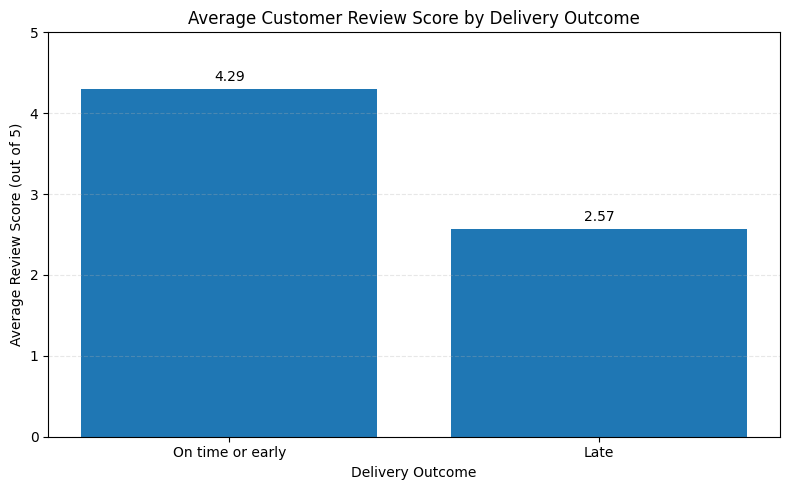

In [11]:

# Plot average review scores by delivery outcome
plot_data = review_summary.reindex(
    ["On time or early", "Late"]
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["average_review_score"]
)

ax.set_title("Average Customer Review Score by Delivery Outcome")
ax.set_xlabel("Delivery Outcome")
ax.set_ylabel("Average Review Score (out of 5)")
ax.set_ylim(0, 5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()



## Business Findings

### 1. Overall Delivery Performance
- 96,470 delivered orders met the eligibility rules for delivery performance analysis.
- 88,644 orders were delivered on time or early, producing an on-time delivery rate of 91.89%.
- 7,826 eligible orders were delivered late.

### 2. Weekday-wise Delivery Performance
- Sunday-purchased orders recorded the highest on-time delivery rate at 92.51%.
- Monday-purchased orders recorded the highest late-delivery rate at 9.05%.
- Friday-purchased orders had the longest average delivery duration at 13.57 days.
- Sunday-purchased orders had the shortest average delivery duration at 11.96 days.
- These are descriptive patterns and do not establish that the purchase weekday caused the outcome.

### 3. State-wise Delivery Performance
- Alagoas (AL) had the lowest on-time delivery rate at 76.07%, based on 397 eligible orders.
- Maranhão (MA) followed at 80.33%, based on 717 eligible orders.
- Rio de Janeiro (RJ) had 12,350 eligible orders and a late-delivery rate of 13.47%.
- State-level differences should be investigated further before attributing them to specific operational causes.

### 4. Customer Review Scores
- Orders delivered on time or early had an average review score of 4.29 out of 5.
- Late-delivered orders had an average review score of 2.57 out of 5.
- The difference was 1.73 points, indicating a strong association between delivery outcome and customer feedback.
- This association does not prove that delivery timing alone caused the rating difference.

### 5. Data Integrity
- No duplicate primary keys were found in the orders, products, or customers tables.
- No unmatched keys were found in the tested joins.
- Order-level review scores were aggregated before merging to prevent duplicate order rows.
- The review join preserved all 96,470 eligible delivery orders.

## Limitations
- Eight orders marked as delivered had missing or invalid actual delivery timestamps and were excluded from the eligible delivery denominator.
- Six hundred forty-six eligible orders had no valid review score available for the comparison.
- The dataset does not provide a delivery carrier identifier, so carrier-level comparisons were not performed.
- The analysis identifies patterns, not proven causes of delivery delays or customer dissatisfaction.

## Week 3 Plan
1. Review these findings with the team and align KPI definitions across deliverables.
2. Investigate potential contributors to late deliveries using available fields, such as customer state, seller, freight value, and order-processing timelines.
3. Compare findings with the team's dashboard and other analysis outputs.
4. Prepare final visualizations and concise business recommendations.
5. Validate the completed notebook, document reproducibility requirements, and integrate the analysis into the project repository.
